<a href="https://colab.research.google.com/github/GuiCastro7/Grupo-3---ECAA08/blob/main/etapa-03-grafos/Aula_20_Algortimo_de_Huffman_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Demonstrativo: Algoritmo de Huffman na Transmissão de Telemetria SCADA-Core (Linha de Envase de Bebidas)

Este notebook demonstra a implementação e simulação do **Algoritmo de Huffman** para compressão sem perdas (*lossless*) de dados de telemetria industrial em tempo real no sistema supervisório **SCADA-Core** (**Grupo 3 — Linha Automatizada de Envasamento e Inspeção de Bebidas**).

---

## 1. Contexto Operacional e Mapeamento de Tags ISA-5.1 na Linha de Envase

Na célula industrial de envasamento e inspeção de bebidas sobre a esteira transportadora `RC1`, o vetor de estado da instrumentação de controle e segurança é composto por 5 sensores críticos:

1. `SP1`: Transmissor de Pressão de Sucção em `TS1`/`BC1` (1 = Anomalia de Pressão $< 1,0\text{ Barg}$ ou $> 3,5\text{ Barg}$)
2. `SP2`: Transmissor de Pressão do Acumulador `AS1` (1 = Sobrepressão Crítica $> 4,5\text{ Barg}$)
3. `SQ2`: Medidor de Vazão Volumétrica de Dosagem em `VS2` (1 = Desvio de Vazão $< 2,0\text{ L/min}$ ou $> 8,0\text{ L/min}$)
4. `SL1`: Sensor Fotoelétrico/Laser de Nível na Garrafa em `VS3` (1 = Nível Insuficiente $< 95\%$ — Garrafa Reprovada)
5. `SFC1`: Sensor Fim de Curso de Integridade de Vedação em `VS5`/`AC1` (1 = Tampa Ausente / Falha Crítica de Selagem)

Sem compressão, cada amostra de telemetria exige uma palavra binária de tamanho fixo de **5 bits** `[SP1, SP2, SQ2, SL1, SFC1]`.

In [1]:
import heapq
import math
import random
import matplotlib.pyplot as plt
import pandas as pd

# Configuração para exibição limpa dos gráficos
%matplotlib inline
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')

## 2. Modelo Probabilístico das Mensagens da Linha de Envase

Devido ao regime sincronizado e estabilizado pelo pulmão hidráulico `AS1` e pela esteira `RC1`, o estado nominal (`00000`) ocorre na imensa maioria das varreduras do CLP, enquanto rejeições de nível (`SL1`), oscilações hidrodinâmicas (`SP1`, `SP2`, `SQ2`) ou falhas críticas de tampagem (`SFC1`) ocorrem com baixa frequência.

In [2]:
# Tabela de probabilidades de cada estado lógico [SP1, SP2, SQ2, SL1, SFC1]
state_probabilities = {
    '00000': 0.900,  # Operação Nominal Estável de Envase e Tampagem
    '00010': 0.050,  # Alarme de Nível Insuficiente < 95% (SL1)
    '10000': 0.025,  # Alarme de Pressão na Sucção TS1/BC1 (SP1)
    '01000': 0.015,  # Alarme de Sobrepressão no Acumulador AS1 (SP2)
    '00100': 0.009,  # Desvio de Vazão no Dosador VS2 (SQ2)
    '00001': 0.001   # Falha Crítica de Vedação / Tampa Ausente (SFC1)
}

state_descriptions = {
    '00000': 'Operação Nominal Estável (Linha OK)',
    '00010': 'Nível Insuficiente na Garrafa (SL1 < 95%)',
    '10000': 'Anomalia de Pressão na Sucção (SP1)',
    '01000': 'Sobrepressão no Acumulador AS1 (SP2)',
    '00100': 'Desvio de Vazão no Envase VS2 (SQ2)',
    '00001': 'Falha de Vedação / Tampa Ausente (SFC1)'
}

df_probs = pd.DataFrame([
    {
        'Vetor de Estado [SP1,SP2,SQ2,SL1,SFC1]': k,
        'Evento na Linha de Envase': state_descriptions[k],
        'Probabilidade': v,
        'Porcentagem (%)': v * 100
    }
    for k, v in state_probabilities.items()
])
print('--- Tabela de Probabilidades de Telemetria (SCADA-Core Grupo 3) ---')
display(df_probs)

--- Tabela de Probabilidades de Telemetria (SCADA-Core Grupo 3) ---


,"Vetor de Estado [SP1,SP2,SQ2,SL1,SFC1]",Evento na Linha de Envase,Probabilidade,Porcentagem (%)
0,00000,Operação Nominal Estável (Linha OK),0.900,90.0
1,00010,Nível Insuficiente na Garrafa (SL1 < 95%),0.050,5.0
2,10000,Anomalia de Pressão na Sucção (SP1),0.025,2.5
3,01000,Sobrepressão no Acumulador AS1 (SP2),0.015,1.5
4,00100,Desvio de Vazão no Envase VS2 (SQ2),0.009,0.9
5,00001,Falha de Vedação / Tampa Ausente (SFC1),0.001,0.1


## 3. Construção da Árvore de Huffman e Geração de Códigos

Implementamos a estrutura de árvore binária ótima e utilizamos uma fila de prioridade (*min-heap*) para gerar os códigos de prefixo de tamanho variável para os estados dos sensores da linha de envase.

In [3]:
class HuffmanNode:
    def __init__(self, symbol=None, freq=0, left=None, right=None):
        self.symbol = symbol
        self.freq = freq
        self.left = left
        self.right = right

    def __lt__(self, other):
        return self.freq < other.freq

def build_huffman_tree(probabilities):
    heap = [HuffmanNode(symbol=sym, freq=p) for sym, p in probabilities.items()]
    heapq.heapify(heap)

    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)
        merged = HuffmanNode(freq=left.freq + right.freq, left=left, right=right)
        heapq.heappush(heap, merged)

    return heap[0]

def generate_codes(root, current_code="", code_dict=None):
    if code_dict is None:
        code_dict = {}
    if root is not None:
        if root.symbol is not None:
            code_dict[root.symbol] = current_code
        generate_codes(root.left, current_code + "0", code_dict)
        generate_codes(root.right, current_code + "1", code_dict)
    return code_dict

# Construir árvore e gerar dicionário
tree_root = build_huffman_tree(state_probabilities)
huffman_codes = generate_codes(tree_root)

print("\n--- Códigos de Huffman Gerados (SCADA-Core Linha de Envase) ---")
for sym, code in sorted(huffman_codes.items(), key=lambda x: len(x[1])):
    print(f"Estado: {sym} ({state_descriptions[sym]:<40}) | Prob: {state_probabilities[sym]:6.3f} | Código Huffman: {code:>5} ({len(code)} bits)")


--- Códigos de Huffman Gerados (SCADA-Core Linha de Envase) ---
Estado: 00000 (Operação Nominal Estável (Linha OK)     ) | Prob:  0.900 | Código Huffman:     1 (1 bits)
Estado: 00010 (Nível Insuficiente na Garrafa (SL1 < 95%)) | Prob:  0.050 | Código Huffman:    00 (2 bits)
Estado: 10000 (Anomalia de Pressão na Sucção (SP1)     ) | Prob:  0.025 | Código Huffman:   011 (3 bits)
Estado: 01000 (Sobrepressão no Acumulador AS1 (SP2)    ) | Prob:  0.015 | Código Huffman:  0101 (4 bits)
Estado: 00001 (Falha de Vedação / Tampa Ausente (SFC1) ) | Prob:  0.001 | Código Huffman: 01000 (5 bits)
Estado: 00100 (Desvio de Vazão no Envase VS2 (SQ2)     ) | Prob:  0.009 | Código Huffman: 01001 (5 bits)


## 4. Simulação de Transmissão SCADA em Tempo Real

Simulamos uma transmissão contínua de **10.000 amostras** de telemetria enviadas pelo CLP da Linha de Envase para o Servidor SCADA-Core central durante a operação da esteira `RC1`.

In [4]:
# Gerar série temporal de dados de amostragem do SCADA-Core (10.000 amostras)
NUM_SAMPLES = 10000
symbols = list(state_probabilities.keys())
weights = list(state_probabilities.values())

random.seed(42)
telemetry_stream = random.choices(symbols, weights=weights, k=NUM_SAMPLES)

# 1. Codificação da transmissão em tamanho fixo (5 bits por amostra)
raw_bitstream = "".join(telemetry_stream)
raw_size_bits = len(raw_bitstream)

# 2. Codificação comprimida via Huffman
compressed_bitstream = "".join([huffman_codes[sym] for sym in telemetry_stream])
compressed_size_bits = len(compressed_bitstream)

print(f"Amostras Processadas na Linha de Envase: {NUM_SAMPLES:,}")
print(f"Tamanho Bruto (Sem Compressão - 5 bits): {raw_size_bits:,} bits ({raw_size_bits/8/1024:.2f} KB)")
print(f"Tamanho Comprimido (Huffman SCADA-Core): {compressed_size_bits:,} bits ({compressed_size_bits/8/1024:.2f} KB)")
print(f"Redução total de tráfego no barramento:  {100 * (1 - compressed_size_bits/raw_size_bits):.2f}%")

Amostras Processadas na Linha de Envase: 10,000
Tamanho Bruto (Sem Compressão - 5 bits): 50,000 bits (6.10 KB)
Tamanho Comprimido (Huffman SCADA-Core): 11,853 bits (1.45 KB)
Redução total de tráfego no barramento:  76.29%


## 5. Algoritmo de Decodificação e Validação Sem Perdas (*Lossless*)

No receptor SCADA-Core, o fluxo binário comprimido é navegado bit a bit através da Árvore de Huffman para reconstruir a sequência exata de leituras dos sensores `[SP1, SP2, SQ2, SL1, SFC1]`.

In [5]:
def decode_huffman(bitstream, root):
    decoded_symbols = []
    current = root
    for bit in bitstream:
        if bit == '0':
            current = current.left
        else:
            current = current.right

        if current.symbol is not None:
            decoded_symbols.append(current.symbol)
            current = root
    return decoded_symbols

# Executar decodificação no receptor SCADA-Core
decoded_telemetry = decode_huffman(compressed_bitstream, tree_root)

# Validação formal de integridade de dados
is_equal = (telemetry_stream == decoded_telemetry)
print(f"Validação de Integridade (Lossless Verification): {'✅ SUCESSO! Recuperação 100% fiel de todas as 10.000 leituras.' if is_equal else '❌ ERRO na integridade!'}")

Validação de Integridade (Lossless Verification): ✅ SUCESSO! Recuperação 100% fiel de todas as 10.000 leituras.


## 6. Análise Teórica e Gráficos de Desempenho

Comparamos os resultados experimentais da telemetria da Linha de Envase com o limite teórico fundamental da **Entropia de Shannon** $H(S)$.

Entropia de Shannon H(S):          0.6480 bits/símbolo
Comprimento Médio da Palavra L:    1.1850 bits/símbolo
Comprimento do Formato Fixo:       5.0000 bits/símbolo
Eficiência Teórica de Compressão:  76.30%


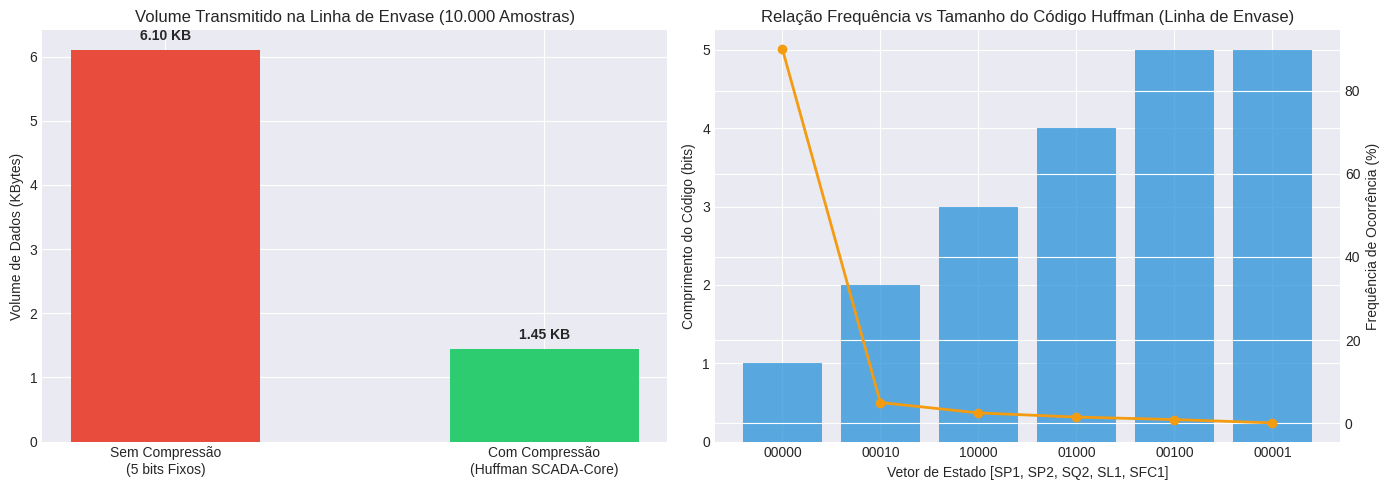

In [6]:
# Entropia de Shannon H(S)
entropy = -sum(p * math.log2(p) for p in state_probabilities.values())

# Comprimento Médio Teórico L
avg_length = sum(state_probabilities[sym] * len(huffman_codes[sym]) for sym in state_probabilities)

print(f"Entropia de Shannon H(S):          {entropy:.4f} bits/símbolo")
print(f"Comprimento Médio da Palavra L:    {avg_length:.4f} bits/símbolo")
print(f"Comprimento do Formato Fixo:       5.0000 bits/símbolo")
print(f"Eficiência Teórica de Compressão:  {(1 - avg_length/5)*100:.2f}%")

# Gráfico comparativo de volume transmitido
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Visualização 1: Comparação de Bits
categories = ['Sem Compressão\n(5 bits Fixos)', 'Com Compressão\n(Huffman SCADA-Core)']
values_kb = [raw_size_bits / 8 / 1024, compressed_size_bits / 8 / 1024]
colors = ['#e74c3c', '#2ecc71']

bars = ax1.bar(categories, values_kb, color=colors, width=0.5)
ax1.set_ylabel('Volume de Dados (KBytes)')
ax1.set_title('Volume Transmitido na Linha de Envase (10.000 Amostras)')
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.1, f'{yval:.2f} KB', ha='center', va='bottom', fontweight='bold')

# Visualização 2: Comprimento dos Códigos vs Probabilidade
states = list(state_probabilities.keys())
probs = [state_probabilities[s]*100 for s in states]
code_lens = [len(huffman_codes[s]) for s in states]

ax2.bar(states, code_lens, color='#3498db', alpha=0.8, label='Tamanho do Código (bits)')
ax2_twin = ax2.twinx()
ax2_twin.plot(states, probs, color='#f39c12', marker='o', linewidth=2, label='Probabilidade (%)')

ax2.set_xlabel('Vetor de Estado [SP1, SP2, SQ2, SL1, SFC1]')
ax2.set_ylabel('Comprimento do Código (bits)')
ax2_twin.set_ylabel('Frequência de Ocorrência (%)')
ax2.set_title('Relação Frequência vs Tamanho do Código Huffman (Linha de Envase)')

plt.tight_layout()
plt.show()